# COU 07506 Digital Signal Processing
## Week 1 — Lab 0: Setting Up the DSP Laboratory
- **NAME:** ABEDNEGO AGUSTINO KUBOKO
- **REGISTRATION NUMBER:** 240647459881
- **DATE:** 23/11/2026
- **GROUP:** ...

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

print("All libraries loaded!")

All libraries loaded!


## Pre-lab Question
Three devices I used today that contain DSP:
1. **Smartphone** — processes my voice during calls
2. **Wi-Fi router** — processes radio signals
3. **TV / decoder** — processes video and audio signals.

## Task 1.1 — Elementary sequences

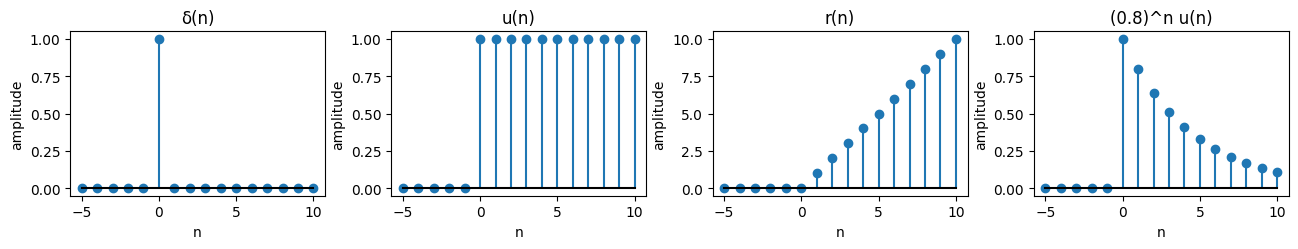

In [9]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel("amplitude")
plt.tight_layout()
plt.show()

## Task 1.2 — Changing the parameters

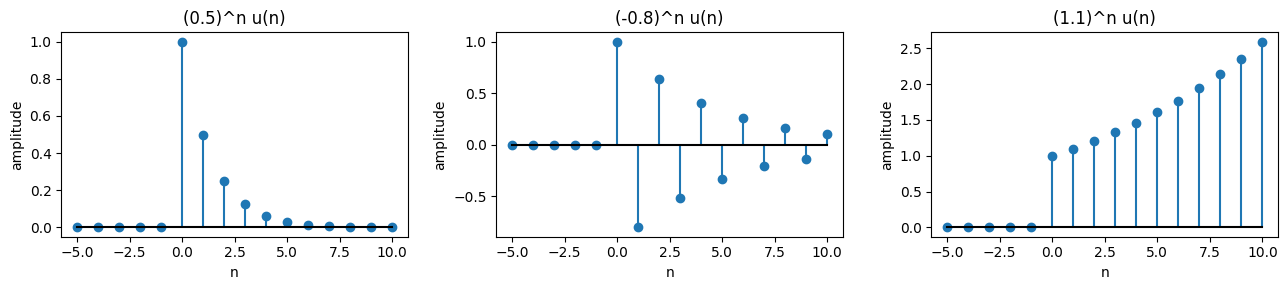

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n * step, basefmt="k-")
    ax.set_title(f"({a})^n u(n)")
    ax.set_xlabel("n")
    ax.set_ylabel("amplitude")
plt.tight_layout()
plt.show()

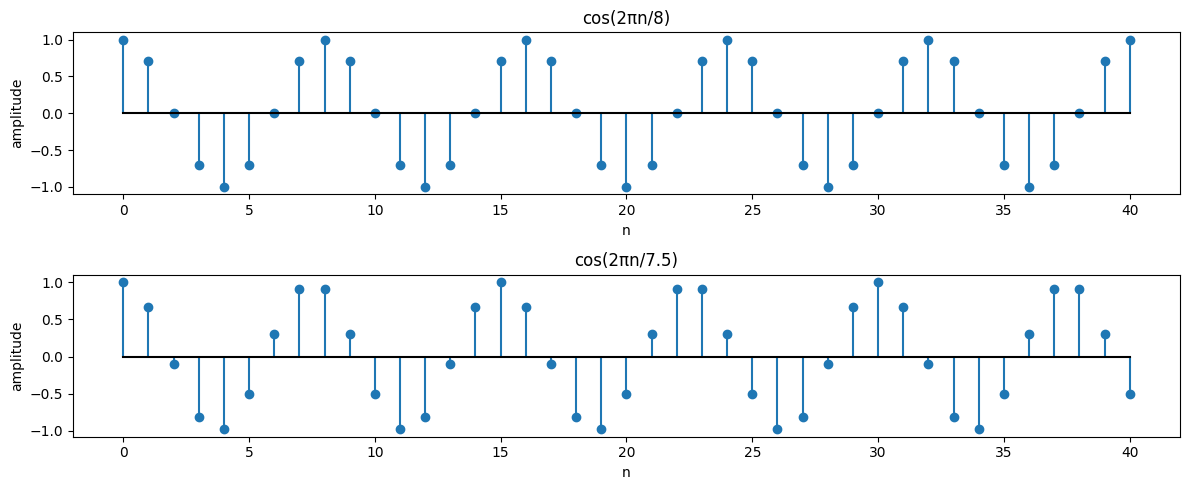

In [11]:
n2 = np.arange(0, 41)
fig, axes = plt.subplots(2, 1, figsize=(12, 5))
axes[0].stem(n2, np.cos(2*np.pi*n2/8), basefmt="k-")
axes[0].set_title("cos(2πn/8)")
axes[1].stem(n2, np.cos(2*np.pi*n2/7.5), basefmt="k-")
axes[1].set_title("cos(2πn/7.5)")
for ax in axes:
    ax.set_xlabel("n")
    ax.set_ylabel("amplitude")
plt.tight_layout()
plt.show()

cos(2πn/8) repeats exactly every 8 samples, because 8 is a whole number. cos(2πn/7.5) cannot repeat every 7.5 samples, because n must be a whole number, it only repeats after 15 samples (two of its cycles). So the first has period N = 8 and the second has period N = 15.

## Task 1.3 — Working with audio

In [12]:
!ffmpeg -y -i Abed.ogg my_voice.wav

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

fs = 48000 Hz, duration = 9.05 s, samples = 434568


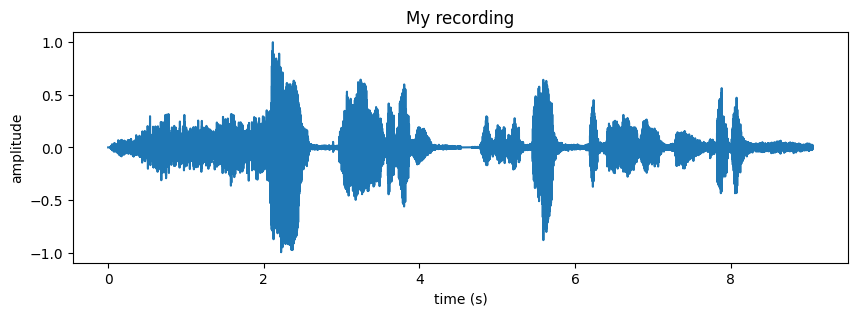

In [13]:
import os
fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.figure(figsize=(10, 3))
plt.plot(t, x)
plt.title("My recording")
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.show()

display(Audio(x, rate=fs))

## Task 1.5 — Repository
My Git repository: https://github.com/abedkb/COU07506-labs

## Analysis Questions

**Question 1. Sampling rate and storage.** My recording has a sampling rate of 48 000 Hz. One minute in mono needs 48 000 × 60 = **2 880 000 numbers** (samples).

**Question 2. Why a stem plot?** x(n) only has values at whole numbers of n; between samples it is not defined. A stem plot shows separate values at each n, while a continuous line would wrongly suggest the signal has values between the samples.

**Question 3. Growing exponential (a = 1.1).** If (1.1)^n u(n) were the impulse response of a system, the system would be **unstable** (not BIBO stable). Its impulse response grows without limit, so the sum of |h(n)| is infinite, and a bounded input could produce an unbounded output.

## AI-use statement
I used Claude to guide me through Lab 0: explaining the code, fixing notebook formatting errors, and helping me phrase my answers. I checked the plots against the expected results in the lab manual and can explain every line of the code.